# Predict concrete strength from mixture composition and curing age

## TASK 1: Explore and write a short report on the data and carryout necessary data preparation, with justification. Establish a mean-prediction baseline.

### Environment Setup and Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")
RANDOM_STATE = 42

# Loading the dataset
df = pd.read_csv("Concrete_Data.csv")

print(f"Dataset Shape: {df.shape}")
print("\nFirst 5 rows:")
display(df.head())

Dataset Shape: (1030, 9)

First 5 rows:


,Cement (kg in a m^3 mixture),Blast Furnace Slag (kg in a m^3 mixture),Fly Ash (kg in a m^3 mixture),Water (kg in a m^3 mixture),Superplasticizer (kg in a m^3 mixture),Coarse Aggregate (kg in a m^3 mixture),Fine Aggregate (kg in a m^3 mixture),Age (day),"Concrete compressive strength (MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


### Data Structure and Quality Checks

In [2]:
print("--- DATA INFO ---")
df.info()

print("\n--- MISSING VALUES ---")
print(df.isna().sum())

print("\n--- DUPLICATES ---")
print(f"Duplicate rows: {df.duplicated().sum()}")

--- DATA INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                                             Non-Null Count  Dtype  
---  ------                                             --------------  -----  
 0   Cement (kg in a m^3 mixture)                       1030 non-null   float64
 1   Blast Furnace Slag (kg in a m^3 mixture)           1030 non-null   float64
 2   Fly Ash (kg in a m^3 mixture)                      1030 non-null   float64
 3   Water (kg in a m^3 mixture)                        1030 non-null   float64
 4   Superplasticizer (kg in a m^3 mixture)             1030 non-null   float64
 5   Coarse Aggregate (kg in a m^3 mixture)             1030 non-null   float64
 6   Fine Aggregate (kg in a m^3 mixture)               1030 non-null   float64
 7   Age (day)                                          1030 non-null   int64  
 8   Concrete compressive strength (MPa, megapascals)   1030 non-null   floa

### Dataset Structure and Data Quality

The dataset contains 1,030 observations and 9 columns, comprising eight numerical predictor variables and one target variable (concrete compressive strength).

The predictor variables describe the composition of concrete mixtures, including cement, blast furnace slag, fly ash, water, superplasticizer, coarse aggregate and fine aggregate. The dataset also includes the age of the concrete in days.

The target variable, concrete compressive strength, is measured in megapascals (MPa).

All nine columns have 1,030 non-null values, indicating that there are no missing values in the dataset. Eight columns are stored as `float64`, while the concrete age variable is stored as `int64`.

The duplicate check identified **25 duplicate rows**. These should be investigated and, if confirmed to be redundant records, removed before further analysis to avoid giving repeated observations additional influence.

Overall, the dataset has no missing values but contains duplicate records that will be handled before proceeding with exploratory data analysis and regression modelling.

### Rename Columns and Handle Duplicates

In [3]:
# 1. Checking for duplicates
dupes = df.duplicated().sum()
print(f"Number of duplicate rows found: {dupes}")

# 2. Dropping them and creating df_clean
df_clean = df.drop_duplicates().reset_index(drop=True)
print(f"Cleaned Shape: {df_clean.shape}")

# 3. Mapping column names
exact_rename = {
    'Cement (kg in a m^3 mixture)': 'cement',
    'Blast Furnace Slag (kg in a m^3 mixture)': 'slag',
    'Fly Ash (kg in a m^3 mixture)': 'fly_ash',
    'Water (kg in a m^3 mixture)': 'water',
    'Superplasticizer (kg in a m^3 mixture)': 'superplasticizer',
    'Coarse Aggregate (kg in a m^3 mixture)': 'coarse_agg',
    'Fine Aggregate (kg in a m^3 mixture)': 'fine_agg',
    'Age (day)': 'age',
    'Concrete compressive strength (MPa, megapascals) ': 'strength'
}

# 4. Renaming the columns
df_clean = df_clean.rename(columns=exact_rename)

print("\nClean Columns:", df_clean.columns.tolist())

Number of duplicate rows found: 25
Cleaned Shape: (1005, 9)

Clean Columns: ['cement', 'slag', 'fly_ash', 'water', 'superplasticizer', 'coarse_agg', 'fine_agg', 'age', 'strength']


**To improve code readability and traceability, the verbose UCI column names were mapped to readable abbreviations. Furthermore, 25 duplicate rows were removed to prevent the model from over-weighting identical concrete mixtures.**

 ### Summary Statistics and Target Distribution

,count,mean,std,min,25%,50%,75%,max
cement,1005.0,278.63,104.35,102.00,190.68,265.0,349.00,540.0
slag,1005.0,72.04,86.17,0.00,0.00,20.0,142.50,359.4
fly_ash,1005.0,55.54,64.21,0.00,0.00,0.0,118.27,200.1
water,1005.0,182.07,21.34,121.75,166.61,185.7,192.94,247.0
superplasticizer,1005.0,6.03,5.92,0.00,0.00,6.1,10.00,32.2
coarse_agg,1005.0,974.38,77.58,801.00,932.00,968.0,1031.00,1145.0
fine_agg,1005.0,772.69,80.34,594.00,724.30,780.0,822.20,992.6
age,1005.0,45.86,63.73,1.00,7.00,28.0,56.00,365.0
strength,1005.0,35.25,16.28,2.33,23.52,33.8,44.87,82.6


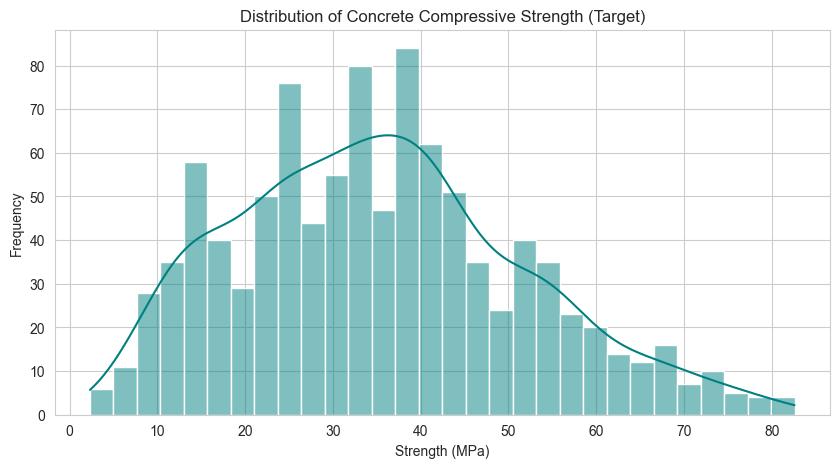

In [4]:
# Summary statistics for all features
display(df_clean.describe().T.round(2))

# Plotting the target distribution
plt.figure(figsize=(10, 5))
sns.histplot(df_clean['strength'], bins=30, kde=True, color='teal')
plt.title("Distribution of Concrete Compressive Strength (Target)")
plt.xlabel("Strength (MPa)")
plt.ylabel("Frequency")
plt.show()

### Exploratory Data Analysis & Feature Scaling

**Summary Statistics:**
The summary statistics reveal a wide range of values across the features. The target variable, `strength`, ranges from 2.33 MPa to 82.6 MPa, with a mean of 35.25 MPa and a median of 33.8 MPa. The ingredients are measured on vastly different scales; for instance, `coarse_agg` ranges up to 1145, while `superplasticizer` maxes out at 32.2. 

Because machine learning algorithms (especially distance-based and linear models) are sensitive to unscaled data, it will be necessary to apply a `StandardScaler` to center and scale the features before modelling. The `age` variable ranges from 1 to 365 days, with a median of 28 days, reflecting standard concrete curing test cycles.

**Target Distribution:**
The histogram of the target variable (`strength`) shows a positively skewed (right-skewed) distribution. Most concrete mixtures in this dataset have a strength between 20 and 45 MPa, with a long tail extending towards 80+ MPa. This skewness suggests that the relationship between ingredients and strength is complex and non-linear, indicating that non-linear tree-based models may outperform linear regression.

### Correlation Matrix

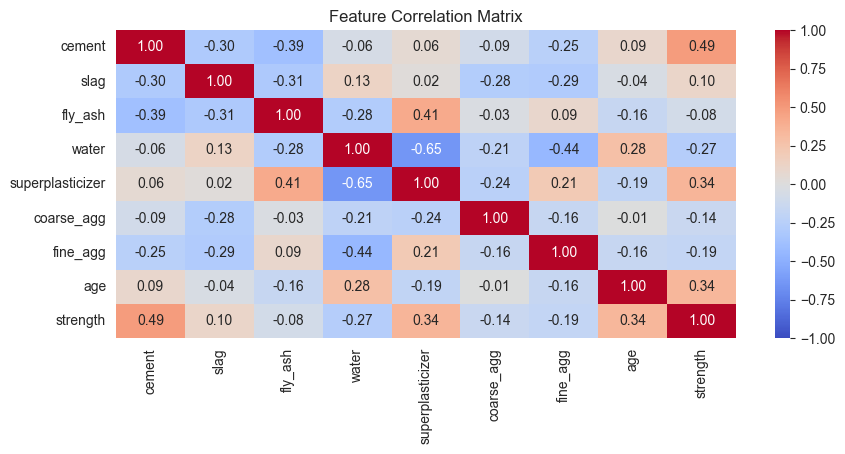

In [5]:
plt.figure(figsize=(10, 4))
correlation_matrix = df_clean.corr()
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Feature Correlation Matrix")
plt.show()

### Correlation Analysis

The correlation matrix reveals several relationships between the concrete mixture components and compressive strength that are consistent with civil engineering principles.

- **Cement (+0.49):** Exhibits the strongest positive linear correlation with concrete compressive strength. This suggests that higher cement content is generally associated with greater strength.
- **Water (-0.27):** Shows a negative correlation with strength. Higher water content, particularly relative to cement content, can increase the water-to-cement ratio and reduce concrete strength.
- **Superplasticizer (+0.34) and Age (+0.34):** Both show positive correlations with strength. Superplasticizers improve workability and can allow water reduction without compromising workability, while concrete age captures the strength development that occurs during curing.

**Multicollinearity Note:** A moderately strong negative correlation exists between water and superplasticizer (-0.65). This relationship is physically plausible because superplasticizers can reduce the amount of water required to achieve the desired workability. This relationship will be investigated further using Variance Inflation Factor (VIF), particularly before fitting linear regression models, as multicollinearity can make regression coefficients unstable.

**Feature-Target Complexity:** Although cement has the strongest individual correlation with concrete strength (+0.49), the relationship is only moderate. This suggests that strength prediction depends on several mixture components and their combined effects, rather than on a single ingredient. For example, the water-to-cement ratio and concrete age may influence strength alongside cement content. 

### Multicollinearity Check (VIF)

In [6]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# 1. Defining the features
X_vif = df_clean.drop(columns=["strength"])

# 2. Adding a constant
X_vif = add_constant(X_vif)

# 3. Calculating VIF for each feature
vif_data = pd.DataFrame()
vif_data["Feature"] = X_vif.columns
vif_data["VIF"] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]

# 4. Dropping the constant from the display and sort by highest VIF
vif_data = vif_data[vif_data["Feature"] != "const"].sort_values(by="VIF", ascending=False)

print("--- VARIANCE INFLATION FACTOR (VIF) ---")
display(vif_data.round(2))

--- VARIANCE INFLATION FACTOR (VIF) ---


,Feature,VIF
1,cement,7.45
2,slag,7.26
7,fine_agg,6.97
4,water,6.84
3,fly_ash,6.09
6,coarse_agg,4.96
5,superplasticizer,2.87
8,age,1.12


### Multicollinearity Analysis (VIF)

To further investigate the correlations observed in the correlation matrix, Variance Inflation Factor (VIF) was calculated for all predictor variables. VIF measures how much the variance of an estimated regression coefficient is inflated due to linear relationships with other predictors. A VIF above 5 is commonly used as an indication of potentially problematic multicollinearity.

The results indicate elevated VIF values among several concrete mixture components, particularly cement (7.45), slag (7.26), fine aggregate (6.97), water (6.84) and fly ash (6.09).

This is partly expected because concrete mixture components are proportionally related through mix design and volume constraints. Changes in the quantity of one ingredient may be accompanied by adjustments to other ingredients to achieve the desired mixture composition.

The presence of multicollinearity may make ordinary least squares (OLS) regression coefficients unstable and difficult to interpret. Therefore, **Ridge Regression** is considered as the linear modelling approach because its L2 regularisation penalises large coefficients and helps reduce coefficient instability.

Tree-based models, including Random Forest and XGBoost, are also considered because they are generally less sensitive to multicollinearity than linear regression, although correlated predictors can still affect feature importance and model interpretation.

### Data Splitting and Preprocessing

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# 1. Defining Features (X) and Target (y)
X = df_clean.drop(columns=["strength"])
y = df_clean["strength"]

# 2. Splitting the data (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Train shape: {X_train.shape}")
print(f"Test shape:  {X_test.shape}")

# 3. Creating a Preprocessing Pipeline
# For regression, StandardScaler helps linear models and neural networks converge faster.
# Tree-based models (Random Forest/XGBoost) don't strictly need it, but it doesn't hurt them.
preprocessor = Pipeline([
    ("scaler", StandardScaler())
])

# Fitting on train, transforming both
X_train_pre = preprocessor.fit_transform(X_train)
X_test_pre  = preprocessor.transform(X_test)

print("Preprocessing complete.")

Train shape: (804, 8)
Test shape:  (201, 8)
Preprocessing complete.


**The dataset was split into an 80% training set and a 20% testing set. Because the feature scales vary significantly (e.g., age ranges from 1-365 days, while aggregates range up to 1000+ kg/m³), a StandardScaler was applied. The scaler was fit strictly on the training data to prevent data leakage.**

### Mean-Prediction Baseline

In [8]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. Initializing and training the dummy model
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train_pre, y_train)

# 2. Predicting on the test set
y_pred_base = baseline.predict(X_test_pre)

# 3. Evaluating
rmse_base = np.sqrt(mean_squared_error(y_test, y_pred_base))
mae_base = mean_absolute_error(y_test, y_pred_base)
r2_base = r2_score(y_test, y_pred_base)

print("--- MEAN-PREDICTION BASELINE ---")
print(f"RMSE: {rmse_base:.2f} MPa")
print(f"MAE:  {mae_base:.2f} MPa")
print(f"R²:   {r2_base:.4f}")

--- MEAN-PREDICTION BASELINE ---
RMSE: 17.30 MPa
MAE:  13.97 MPa
R²:   -0.0028


### Mean-Prediction Baseline

To establish a baseline for evaluating model performance, a mean-prediction model was created using `DummyRegressor`. The model predicts the average concrete compressive strength from the training data for every observation in the test set.

The baseline achieved the following results:

- **RMSE:** 17.30 MPa
- **R²:** -0.0028 (approximately 0)

The results indicate that simply predicting the average concrete strength provides very little predictive value. The slightly negative R² suggests that the baseline performs marginally worse than predicting the actual mean of the test-set values.

Therefore, subsequent machine learning models should aim to achieve a lower RMSE and a higher R², preferably a positive value, to demonstrate an improvement over the baseline.

## Compare the performance of linear and non-linear modeling approaches. Inspect residuals and identify where predictions are weakest. (Ensure to indicate supporting evidence).

 ### Comparing Linear and Non-Linear Models



In [9]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import cross_validate, KFold
import pandas as pd

print("--- MODEL CROSS-VALIDATION ---")

# Defining models
models = {
    "Linear (Ridge)": Ridge(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    "XGBoost": XGBRegressor(random_state=42, n_jobs=-1)
}

# For regression, KFold is used (not StratifiedKFold)
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Metrics: negative MSE (scikit-learn convention), R2
scoring = ["neg_mean_squared_error", "r2"]

results = []

for name, model in models.items():
    print(f"Training {name}...")
    cv_results = cross_validate(model, X_train_pre, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    
    # Calculating RMSE from the negative MSE
    rmse_scores = np.sqrt(-cv_results["test_neg_mean_squared_error"])
    
    results.append({
        "Model": name,
        "RMSE (mean)": rmse_scores.mean(),
        "R² (mean)": cv_results["test_r2"].mean()
    })

results_df = pd.DataFrame(results).set_index("Model").round(3)
display(results_df)

--- MODEL CROSS-VALIDATION ---
Training Linear (Ridge)...
Training Random Forest...
Training XGBoost...


,RMSE (mean),R² (mean)
Model,,
Linear (Ridge),10.203,0.589
Random Forest,5.353,0.886
XGBoost,4.972,0.902


### Comparison of Linear vs. Non-Linear Models

Three models were evaluated using 5-fold cross-validation: Ridge Regression (linear), Random Forest (non-linear bagging), and XGBoost (non-linear boosting).

| Model | RMSE (Mean) | R² (Mean) |
| :--- | :--- | :--- |
| **XGBoost** | **4.972 MPa** | **0.902** |
| **Random Forest** | 5.353 MPa | 0.886 |
| **Ridge Regression** | 10.203 MPa | 0.589 |

**Interpretation:**

The non-linear models substantially outperform Ridge Regression. XGBoost achieves the best performance, with a mean RMSE of 4.972 MPa and an R² of 0.902. This means that the model explains approximately 90.2% of the variation in concrete compressive strength across the cross-validation folds, with an average prediction error of approximately 5 MPa.

Ridge Regression, despite standardisation and L2 regularisation to address coefficient instability associated with multicollinearity, achieves a lower R² of 0.589 and a higher RMSE of 10.203 MPa.

The performance difference suggests that the relationships between concrete mixture components and compressive strength are not adequately captured by a simple linear model. These relationships may involve non-linear effects and interactions between ingredients. For example, the effect of water content on concrete strength is influenced by the water-to-cement ratio, while concrete age captures strength development during curing.

Tree-based models such as Random Forest and XGBoost can capture complex relationships and interactions between predictors, which likely contributes to their better performance.

**Conclusion:** XGBoost is the best-performing model among the three evaluated and will be considered for further model evaluation and interpretation.

### Residual Analysis

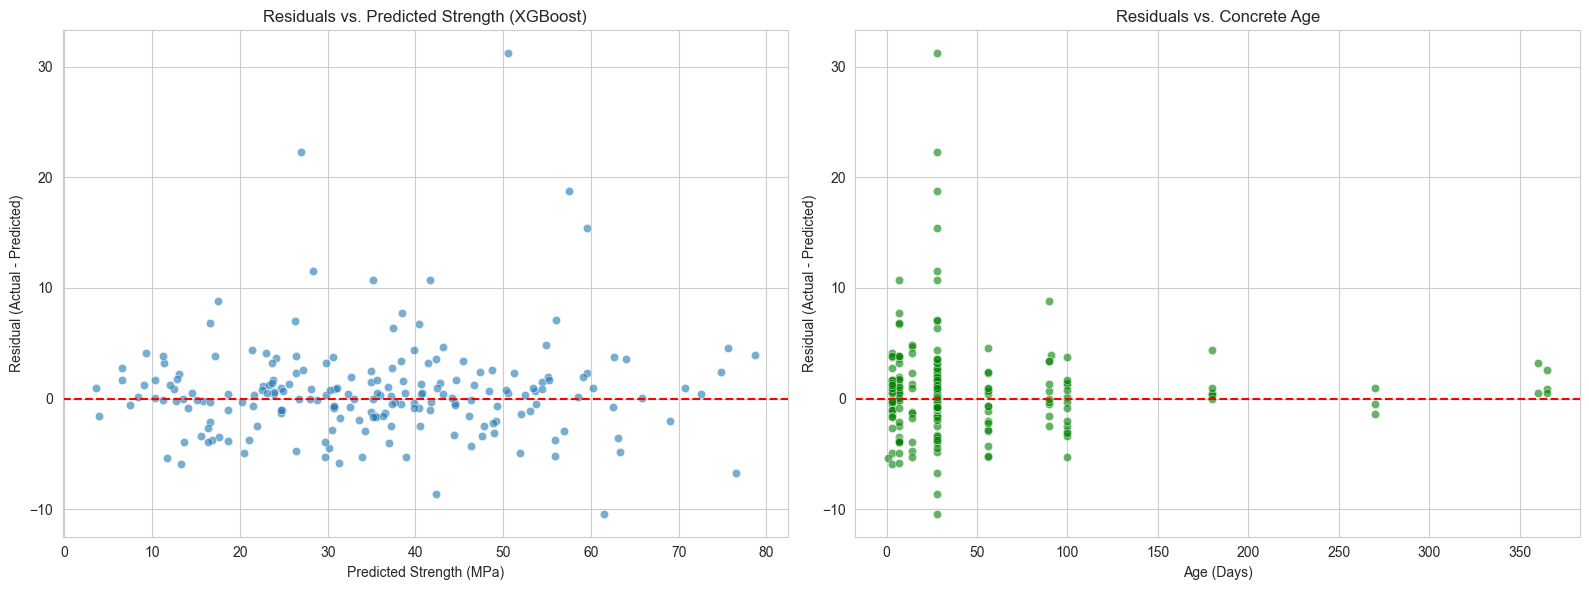

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBRegressor

# 1. Training the winning model on the full training set
best_model = XGBRegressor(random_state=42, n_jobs=-1)

best_model.fit(X_train_pre, y_train)

# 2. Predicting on the test set
y_pred = best_model.predict(X_test_pre)

# 3. Calculating residuals
residuals = y_test - y_pred

# 4. Creating plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Residuals vs. Predicted Values
sns.scatterplot(x=y_pred, y=residuals, alpha=0.6, ax=axes[0])
axes[0].axhline(y=0, color='r', linestyle='--')
axes[0].set_title("Residuals vs. Predicted Strength (XGBoost)")
axes[0].set_xlabel("Predicted Strength (MPa)")
axes[0].set_ylabel("Residual (Actual - Predicted)")

# Plot 2: Residuals vs. Age
sns.scatterplot(x=X_test['age'], y=residuals, alpha=0.6, ax=axes[1], color='green')
axes[1].axhline(y=0, color='r', linestyle='--')
axes[1].set_title("Residuals vs. Concrete Age")
axes[1].set_xlabel("Age (Days)")
axes[1].set_ylabel("Residual (Actual - Predicted)")

plt.tight_layout()
plt.show()

### Evaluate prediction errors by concrete age

In [11]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Creating a DataFrame containing actual values, predictions and concrete age
results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred,
    "Age": X_test["age"].values
})

# Calculating residuals and absolute errors
results["Residual"] = results["Actual"] - results["Predicted"]
results["Absolute Error"] = results["Residual"].abs()

# Grouping concrete observations by age
results["Age Group"] = pd.cut(
    results["Age"],
    bins=[0, 7, 28, np.inf],
    labels=["<7 days", "7–27 days", "28+ days"],
    right=False
)

# Calculating performance metrics for each age group
age_performance = results.groupby("Age Group", observed=False).apply(
    lambda group: pd.Series({
        "Observations": len(group),
        "MAE (MPa)": mean_absolute_error(group["Actual"], group["Predicted"]),
        "RMSE (MPa)": np.sqrt(mean_squared_error(group["Actual"], group["Predicted"]))
    }),
    include_groups=False
)

print("Model Performance by Concrete Age:")
display(age_performance.round(2))

Model Performance by Concrete Age:


,Observations,MAE (MPa),RMSE (MPa)
Age Group,,,
<7 days,27.0,1.94,2.53
7–27 days,41.0,3.12,3.88
28+ days,133.0,2.78,5.02


### Evaluate prediction errors by predicted-strength range

In [12]:
# Grouping observations according to predicted concrete strength
results["Predicted Strength Group"] = pd.cut(
    results["Predicted"],
    bins=[-np.inf, 20, 50, 60, np.inf],
    labels=["<20 MPa", "20–49.9 MPa", "50–59.9 MPa", "60+ MPa"],
    right=False
)

# Calculating performance metrics for each predicted-strength group
strength_performance = results.groupby(
    "Predicted Strength Group", observed=False
).apply(
    lambda group: pd.Series({
        "Observations": len(group),
        "MAE (MPa)": mean_absolute_error(group["Actual"], group["Predicted"]),
        "RMSE (MPa)": np.sqrt(mean_squared_error(group["Actual"], group["Predicted"]))
    }),
    include_groups=False
)

print("Model Performance by Predicted Strength:")
display(strength_performance.round(2))

Model Performance by Predicted Strength:


,Observations,MAE (MPa),RMSE (MPa)
Predicted Strength Group,,,
<20 MPa,39.0,2.30,3.09
20–49.9 MPa,122.0,2.45,3.80
50–59.9 MPa,25.0,4.52,8.35
60+ MPa,15.0,3.27,4.22


### Check the direction of prediction errors

In [13]:
# Calculating average residual for each predicted-strength group
error_direction = results.groupby(
    "Predicted Strength Group", observed=False
)["Residual"].agg(
    ["count", "mean", "min", "max"]
).round(2)

print("Residual Summary by Predicted Strength:")
display(error_direction)

Residual Summary by Predicted Strength:


,count,mean,min,max
Predicted Strength Group,,,,
<20 MPa,39,0.07,-5.92,8.85
20–49.9 MPa,122,0.50,-8.65,22.33
50–59.9 MPa,25,2.94,-5.18,31.21
60+ MPa,15,-0.51,-10.42,4.57


### Residual Analysis and Weakest Predictions

To identify where the XGBoost model performs weakest, residuals (Actual Strength - Predicted Strength) were plotted against predicted strength and concrete age. Additional MAE and RMSE comparisons were performed across different strength and age groups.

**1. Residuals vs. Predicted Strength:**

The residual plot shows that most predictions between 20 and 50 MPa are relatively close to the zero line, indicating reasonably accurate predictions. However, some observations have substantially larger residuals, particularly in the mid-to-high strength range.

The quantitative comparison identifies the 50–59.9 MPa group as having the largest prediction errors, with an MAE of 4.52 MPa and an RMSE of 8.35 MPa across 25 observations. Its mean residual is also positive (+2.94 MPa), indicating a tendency to underpredict concrete strength in this range.

Although the 60+ MPa group contains some large residuals, its RMSE is lower (4.22 MPa), and its mean residual is -0.51 MPa. Therefore, the model does not consistently underpredict concrete strength above 60 MPa.

**2. Residuals vs. Concrete Age:**

The residual plot shows considerable variation in prediction errors across concrete ages. The quantitative comparison indicates that concrete aged 28 days or more has the highest RMSE (5.02 MPa), compared with 3.88 MPa for concrete aged 7–27 days and 2.53 MPa for concrete aged less than seven days.

However, the 7–27-day group has the highest MAE (3.12 MPa), suggesting that its average absolute prediction error is slightly higher than that of the older concrete group (2.78 MPa).

**Supporting Evidence and Interpretation:**

Overall, the model performs reasonably well across most observations but has greater difficulty predicting certain concrete mixtures. The 50–59.9 MPa predicted-strength group shows the weakest performance based on both MAE and RMSE. The higher RMSE for concrete aged 28 days or more also indicates the presence of some larger prediction errors in this age group.

## TASK 3: Does a predictive association between cement content and strength prove what will happen in the real-world if we change the mixture? Justify your answer.

### Causation vs. Correlation in Concrete Strength

**Question:** Does a predictive association between cement content and strength prove what will happen in the real world if we change the mixture?

**Answer:** No. A positive association (such as the +0.49 correlation observed earlier) does not prove causation. There are several reasons why:

1. **Observational Data Limitations:** This dataset is observational rather than the result of a controlled experiment. The mixtures reflect existing formulations tested under different conditions, rather than mixtures in which cement content was randomly varied to measure its effect on strength.

2. **Confounding Variables:** Concrete strength is influenced by several interrelated factors, including water content, aggregate composition, superplasticizer and curing conditions. For example, increasing cement content while keeping water content constant changes the water-to-cement ratio, which can influence strength. The model learns patterns from existing mixtures; it does not establish what would happen if an engineer deliberately changed cement content.

3. **Model Extrapolation:** Machine learning models learn patterns from the data used during training. If an engineer introduces a cement content or mixture composition outside the range represented in the dataset, the model's predictions may be unreliable. However, even predictions within the observed data range do not establish causation.

**Conclusion:** To establish the causal effect of changing cement content, controlled physical experiments could be conducted in which cement content is deliberately varied while other relevant mixture conditions are controlled. This would help determine whether changes in cement content directly cause changes in concrete compressive strength.